# Who Captures the Value of AI Medical Scribes? Data and calculations

Companion notebook to the report *Who Captures the Value of AI Medical Scribes? Generative AI, Clinical Documentation and Platform Strategy in Primary Care, 2024–2026* (Lara Normand, E-Business & Digital Disruption, ESSEC Business School, 2026).

It reproduces every value marked **“author’s calculation”** in the report and **Figure 2**:

| Report section | Calculation |
|---|---|
| 4.3 | Monthly documentation time released; break-even of the €64–79 subscription; gross receipts from extra visits |
| 5.1 | Patient accounts per paying professional |
| 5.3 | Theoretical GP time released in France if half of GPs used a scribe |
| 5.3, Figure 2 | Reported ARR (2024, 2025) and illustrative subscription receipts (scribe and patient side) |

**Data.** All inputs are in `report_data.csv`: each row is *data* (with its APA reference, as in the report), an *assumption* or a *scenario*. Scenarios are illustrative gross receipts, not forecasts, and are not comparable with reported ARR.

**How to run.** Python 3 with `pandas` and `matplotlib`; run all cells. The last section checks each computed value against the value written in the report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False})
df = pd.read_csv("report_data.csv")
V = dict(zip(df["id"], df["value"]))
data = df[df["type"] == "data"]
unchecked = (data["checked_by_student"].astype(str).str.lower() != "true").sum()
print(f"{len(df)} inputs: {len(data)} data points, {(df['type']=='assumption').sum()} assumptions, "
      f"{(df['type']=='scenario').sum()} scenarios.")
print(f"Data points still to check against their source: {unchecked}")
df[["parameter", "value", "unit", "type", "reference"]]

21 inputs: 11 data points, 4 assumptions, 6 scenarios.
Data points still to check against their source: 11


,parameter,value,unit,type,reference
0,Doctolib annual recurring revenue 2024,3.480000e+08,EUR,data,Leprince-Ringuet (2025)
1,Doctolib annual recurring revenue 2025,4.220000e+08,EUR,data,Caravagna (2026)
2,Share of ARR from professional subscriptions (...,9.900000e-01,share,data,Leprince-Ringuet (2025)
3,Paying health professionals (2024),4.000000e+05,professionals,data,Leprince-Ringuet (2025)
4,Patient accounts (2024),8.000000e+07,accounts,data,Leprince-Ringuet (2025)
5,Standalone consultation assistant price (lower...,6.400000e+01,EUR per month,data,Doctolib (n.d.-a)
6,Standalone consultation assistant price (highe...,7.900000e+01,EUR per month,data,Doctolib (n.d.-a)
7,Doctolib+ subscription (Doctolib Parents) from,4.990000e+00,EUR per month,data,Doctolib (n.d.-b)
8,Documentation minutes saved per 8 hours of sch...,1.600000e+01,minutes,data,Rotenstein et al. (2026)
9,Additional visits per week after adoption,4.900000e-01,visits per week,data,Rotenstein et al. (2026)


## 1. Section 4.3. Time released, break-even and extra visits

In [2]:
hours_month = V["doc_minutes_saved_per_8h"] * V["working_days_month"] / 60
break_even_low = V["scribe_price_low"] / V["gp_hour_value"] * 60
break_even_high = V["scribe_price_high"] / V["gp_hour_value"] * 60
visits_receipts = V["extra_visits_per_week"] * 52 / 12 * V["consultation_fee"]
print(f"Monthly time released: {hours_month:.2f} hours")
print(f"Break-even at €{V['gp_hour_value']:.0f}/h: {break_even_low:.1f}–{break_even_high:.1f} minutes per month")
print(f"Gross receipts from extra visits: €{visits_receipts:.2f} per month")

Monthly time released: 5.33 hours
Break-even at €120/h: 32.0–39.5 minutes per month
Gross receipts from extra visits: €63.70 per month


## 2. Section 5.1. Platform ratio

In [3]:
ratio = V["patient_accounts"] / V["paying_professionals"]
print(f"Patient accounts per paying professional: {ratio:,.0f}")

Patient accounts per paying professional: 200


## 3. Section 5.3. Theoretical GP time released in France

In [4]:
gp_time_equivalent = V["gps_france"] * V["adoption_state_scenario"] * V["doc_minutes_saved_per_8h"] / V["schedule_minutes"]
print(f"{V['gps_france']:,.0f} × {V['adoption_state_scenario']:.0%} × {V['doc_minutes_saved_per_8h']:.0f}/{V['schedule_minutes']:.0f}"
      f" = {gp_time_equivalent:,.0f} full-time eight-hour care schedules")

101,000 × 50% × 16/480 = 1,683 full-time eight-hour care schedules


## 4. Figure 2. Reported ARR and illustrative subscription receipts

Scribe bars show the €64–79 price range (solid part = lower price, hatched part = range). The patient price uses €5 a month, the Doctolib+ price (from €4.99) rounded.

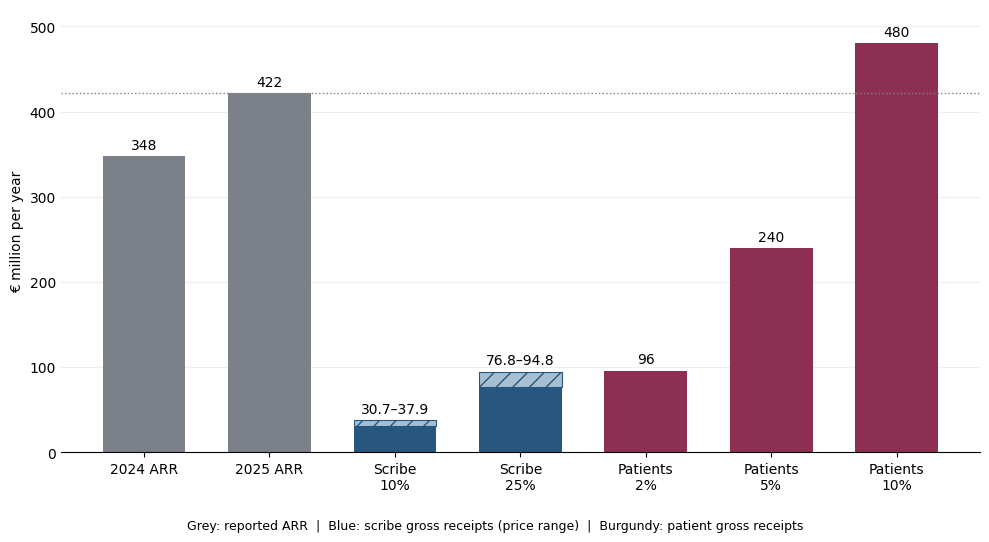

,bar,low (€m),high (€m)
0,2024 ARR,348.0,348.0
1,2025 ARR,422.0,422.0
2,Scribe 10%,30.7,37.9
3,Scribe 25%,76.8,94.8
4,Patients 2%,96.0,96.0
5,Patients 5%,240.0,240.0
6,Patients 10%,480.0,480.0


In [5]:
pp = round(V["patient_price"])
scribe = {f"Scribe\n{a:.0%}": (V["paying_professionals"] * a * V["scribe_price_low"] * 12 / 1e6,
                                 V["paying_professionals"] * a * V["scribe_price_high"] * 12 / 1e6)
          for a in [V["scribe_adoption_low"], V["scribe_adoption_high"]]}
patients = {f"Patients\n{p:.0%}": V["patient_accounts"] * p * pp * 12 / 1e6
            for p in [V["patient_paying_low"], V["patient_paying_mid"], V["patient_paying_high"]]}
GREY, BLUE, LBLUE, BURG = "#7C8089", "#27577E", "#A7BED3", "#8C2F52"

fig, ax = plt.subplots(figsize=(10, 5.4))
labels, x = [], 0
for name, v in [("2024 ARR", V["arr_2024"] / 1e6), ("2025 ARR", V["arr_2025"] / 1e6)]:
    ax.bar(x, v, width=0.66, color=GREY); ax.text(x, v + 8, f"{v:,.0f}", ha="center"); labels.append(name); x += 1
for name, (lo, hi) in scribe.items():
    ax.bar(x, lo, width=0.66, color=BLUE)
    ax.bar(x, hi - lo, bottom=lo, width=0.66, color=LBLUE, hatch="//", edgecolor=BLUE, linewidth=0.8)
    ax.text(x, hi + 8, f"{lo:.1f}–{hi:.1f}", ha="center"); labels.append(name); x += 1
for name, v in patients.items():
    ax.bar(x, v, width=0.66, color=BURG); ax.text(x, v + 8, f"{v:,.0f}", ha="center"); labels.append(name); x += 1
ax.axhline(V["arr_2025"] / 1e6, color="grey", ls=":", lw=1)
ax.set_xticks(range(len(labels)), labels); ax.set_ylabel("€ million per year"); ax.set_ylim(0, 520)
ax.yaxis.grid(True, color="#EEEEEE"); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
fig.text(0.5, 0.01, "Grey: reported ARR  |  Blue: scribe gross receipts (price range)  |  Burgundy: patient gross receipts",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig("fig2_scenarios.png", dpi=300); plt.show()
fig2 = pd.DataFrame([("2024 ARR", V["arr_2024"]/1e6, V["arr_2024"]/1e6), ("2025 ARR", V["arr_2025"]/1e6, V["arr_2025"]/1e6)]
                    + [(k.replace("\n", " "), lo, hi) for k, (lo, hi) in scribe.items()]
                    + [(k.replace("\n", " "), v, v) for k, v in patients.items()], columns=["bar", "low (€m)", "high (€m)"])
fig2.round(1)

## 5. Check against the values written in the report

In [6]:
written = [
    ("4.3 Monthly time released (just over five hours)", hours_month, 5.33),
    ("4.3 Break-even, lower price (32 minutes)", break_even_low, 32),
    ("4.3 Break-even, higher price (about 40 minutes)", break_even_high, 39.5),
    ("4.3 Extra visits (about €64 a month)", visits_receipts, 63.70),
    ("5.1 Accounts per professional (around 200)", ratio, 200),
    ("5.3 GP time released (around 1,700; 1,683 before rounding)", gp_time_equivalent, 1683),
    ("Fig. 2 Scribe 10% (30.7–37.9)", sum(scribe["Scribe\n10%"]) / 2, (30.7 + 37.9) / 2),
    ("Fig. 2 Scribe 25% (76.8–94.8)", sum(scribe["Scribe\n25%"]) / 2, (76.8 + 94.8) / 2),
    ("Fig. 2 Patients 2% / 5% / 10% (96 / 240 / 480)", sum(patients.values()), 96 + 240 + 480),
]
res = pd.DataFrame([(n, round(c, 2), w, abs(c - w) <= max(0.01 * w, 0.06)) for n, c, w in written],
                   columns=["value in the report", "computed", "written", "consistent"])
print("All consistent:", bool(res["consistent"].all()))
res

All consistent: True


,value in the report,computed,written,consistent
0,4.3 Monthly time released (just over five hours),5.33,5.33,True
1,"4.3 Break-even, lower price (32 minutes)",32.00,32.00,True
2,"4.3 Break-even, higher price (about 40 minutes)",39.50,39.50,True
3,4.3 Extra visits (about €64 a month),63.70,63.70,True
4,5.1 Accounts per professional (around 200),200.00,200.00,True
5,"5.3 GP time released (around 1,700; 1,683 befo...",1683.33,1683.00,True
6,Fig. 2 Scribe 10% (30.7–37.9),34.32,34.30,True
7,Fig. 2 Scribe 25% (76.8–94.8),85.80,85.80,True
8,Fig. 2 Patients 2% / 5% / 10% (96 / 240 / 480),816.00,816.00,True


## Limits

- Time savings come from American academic centres (Rotenstein et al., 2026) and have not been validated in French general practice.
- The €120 hourly value, the €30 consultation fee and 20 working days are illustrative assumptions.
- Adoption and conversion shares are assumptions applied to historical platform-wide user counts, not measured adoption.
- Subscription scenarios are annualised gross receipts before taxes, costs, discounts and churn; they are not comparable with reported ARR or necessarily incremental to it.